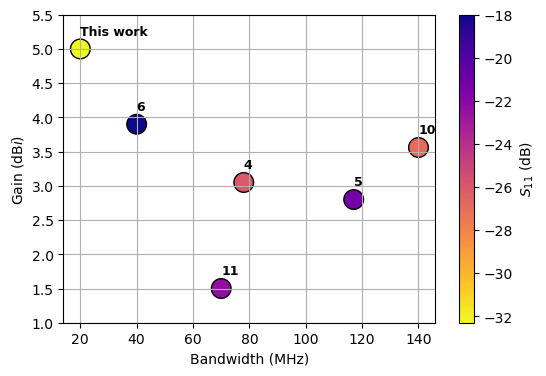

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
df = pd.read_csv('antenna_comparison.csv')

# Create the figure
plt.figure(figsize=(6,4))

# Create a scatter plot: 
# x-axis: Bandwidth (MHz)
# y-axis: Gain (dBi)
# color (c): S11 (dB) to create the "heatmap" effect
# cmap: 'viridis_r' (reversed viridis) so lower S11 values (better) are distinct
sc = plt.scatter(df['Bandwidth (MHz)'], 
                 df['Gain (dBi)'], 
                 c=df['𝑆11 (dB)'], 
                 cmap='plasma_r', 
                 s=200, 
                 edgecolors='black', 
                 linewidth=1)

# Add a colorbar to represent the S11 (dB) heatmap scale
cbar = plt.colorbar(sc)
cbar.set_label('$S_{11}$ (dB)')

# Annotate each point with its corresponding Reference (Ref.)
for i, txt in enumerate(df["Reference"]):
    # Slightly offset the text labels for better readability
    plt.annotate(txt, 
                 (df['Bandwidth (MHz)'][i], df['Gain (dBi)'][i]), 
                 textcoords="offset points", 
                 xytext=(0, 10), 
                 ha='left', 
                 fontsize=9, 
                 weight='bold')

# Set labels and title
plt.xlabel('Bandwidth (MHz)')
plt.ylim(1,5.5)
plt.ylabel('Gain (dB$ {i}$)')

# Add grid for better scale perception
plt.grid(True)

# Save the visualization
#plt.savefig('comparisionheatmap.png', dpi=300)

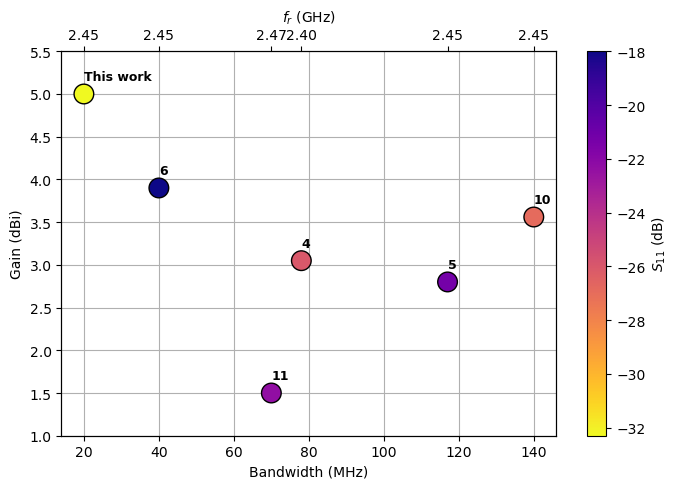

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the data from the CSV file
df = pd.read_csv('antenna_comparison.csv')

# Define column names based on the file inspection
col_fr = '𝑓𝑟 (GHz)'
col_s11 = '𝑆11 (dB)'
col_bw = 'Bandwidth (MHz)'
col_gain = 'Gain (dBi)'

# Create the figure and primary axis
fig, ax1 = plt.subplots(figsize=(7, 5))

# Create a scatter plot on ax1
# Color (c): S11 (dB) heatmap effect using 'plasma_r' colormap
sc = ax1.scatter(df[col_bw], 
                 df[col_gain], 
                 c=df[col_s11], 
                 cmap='plasma_r', 
                 s=200, 
                 edgecolors='black', 
                 linewidth=1,
                 zorder=3)

# Add a colorbar for the S11 (dB) heatmap
cbar = fig.colorbar(sc, ax=ax1)
cbar.set_label('$S_{11}$ (dB)')

# Annotate each point with its corresponding Reference (Ref.)
for i, row in df.iterrows():
    ax1.annotate(row['Reference'], 
                 (row[col_bw], row[col_gain]), 
                 textcoords="offset points", 
                 xytext=(0, 10), 
                 ha='left', 
                 fontsize=9, 
                 weight='bold')

# Set labels, limits, and grid for the primary (bottom) axis
ax1.set_xlabel('Bandwidth (MHz)')
ax1.set_ylabel('Gain (dBi)')
ax1.set_ylim(1, 5.5)
ax1.grid(True)

# Create the secondary (upper) x-axis for Frequency (fr)
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())

# Set ticks at the bandwidth values and label them with the frequency values
ax2.set_xticks(df[col_bw])
ax2.set_xticklabels([f"{e:.2f}" for e in df[col_fr]])
ax2.set_xlabel('$f_r$ (GHz)')

# Adjust layout to prevent clipping and save the image
plt.tight_layout()
plt.savefig('antenna_comparison_heatmap.png', dpi=300)

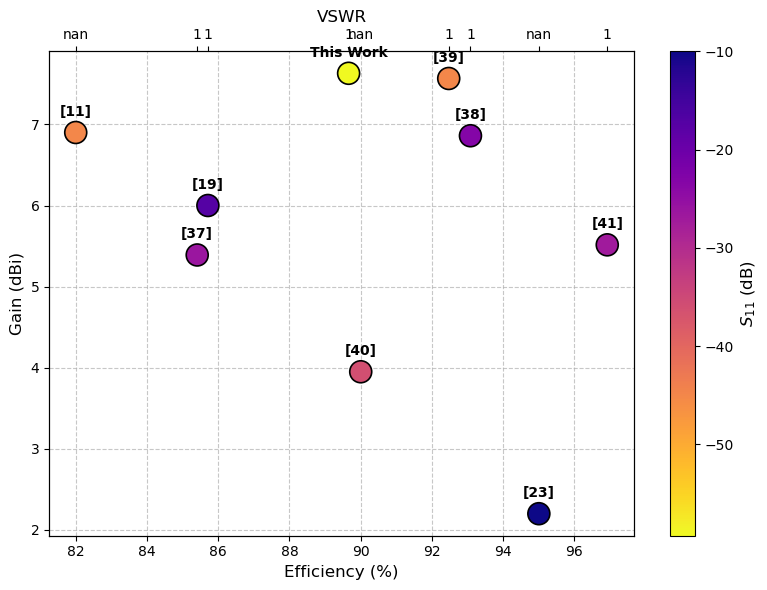

In [17]:
import pandas as pd
import io
import matplotlib.pyplot as plt
import numpy as np

# Data provided by the user
data = """Ref,fr (GHz),S11 (dB),VSWR,Gain (dBi),Directivity (dBi),Efficiency (%)
[11],28,-45,-,6.9,-,82
[23],28,≤ -10,-,2.2,-,95
[19],28,-17.28,1.31,6,7,85.71
[37],28,-26.24,1.054,5.39,6.31,85.41
[38],28,-23.14,1.14,6.86,7.37,93.08
[39],28,-45,1.067,7.566,8.182,92.47
[40],28,-36,-,3.95,-,90
[41],28,-27.04,1.095,5.515,5.690,96.92
[42],28,-22.51,1.25,3.6,-,-
[43],28,-,1.3,6.08,7.16,85
This Work,28,-59.29,1.002,7.63,8.51,89.66"""

# Load data
df = pd.read_csv(io.StringIO(data))

# Data Cleaning
def clean_numeric(val):
    if pd.isna(val) or val == '-':
        return np.nan
    if isinstance(val, str):
        val = val.replace('≤', '').replace(' ', '')
    try:
        return float(val)
    except ValueError:
        return np.nan

df['S11_clean'] = df['S11 (dB)'].apply(clean_numeric)
df['Gain_clean'] = df['Gain (dBi)'].apply(clean_numeric)
df['Eff_clean'] = df['Efficiency (%)'].apply(clean_numeric)
df['VSWR_clean'] = df['VSWR'].apply(clean_numeric)

# Drop rows missing crucial plotting data (Gain, S11, or Efficiency)
# We use Efficiency (%) as the primary X-axis since Bandwidth is missing in this dataset
plot_df = df.dropna(subset=['Gain_clean', 'S11_clean', 'Eff_clean']).reset_index(drop=True)

# Create the figure
fig, ax1 = plt.subplots(figsize=(8, 6))

# Scatter plot: x=Efficiency, y=Gain, color=S11
sc = ax1.scatter(plot_df['Eff_clean'],
                 plot_df['Gain_clean'],
                 c=plot_df['S11_clean'],
                 cmap='plasma_r',
                 s=250,
                 edgecolors='black',
                 linewidth=1.2,
                 zorder=3)

# Colorbar for S11
cbar = fig.colorbar(sc, ax=ax1)
cbar.set_label('$S_{11}$ (dB)', fontsize=12)

# Annotations
for i, row in plot_df.iterrows():
    ax1.annotate(row['Ref'],
                 (row['Eff_clean'], row['Gain_clean']),
                 textcoords="offset points",
                 xytext=(0, 12),
                 ha='center',
                 fontsize=10,
                 weight='bold')

# Primary Axis Formatting
ax1.set_xlabel('Efficiency (%)', fontsize=12)
ax1.set_ylabel('Gain (dBi)', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.7, zorder=0)

# Secondary Top Axis for Frequency (fr)
ax2 = ax1.twiny()
ax2.set_xlim(ax1.get_xlim())
# Set ticks at the efficiency values of the data points
ax2.set_xticks(plot_df['Eff_clean'])
# Label with frequency values (all are 28 in this set)
ax2.set_xticklabels([f"{v:.0f}" for v in plot_df['VSWR_clean']])
ax2.set_xlabel('VSWR', fontsize=12)

plt.tight_layout()
plt.savefig('antenna_comparison_v2 with VSWR.png', dpi=300)

# Save the cleaned data for the user
#plot_df.to_csv('cleaned_antenna_comparison with VSWR.csv', index=False)